
# Versuch 2: Kalibrierung von Digitalkameras

## 1. Aufnahme und Analyse eines Grauwertkeiles

### 1.1 Einlesen und Darstellung

Das aufgenommene Bild wird eingelesen und in ein Grauwertbild umgewandelt.


In [2]:
%pip install opencv-python


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 30.8 MB/s  0:00:02 eta 0:00:010:01:01
Note: you may need to restart the kernel to use updated packages.


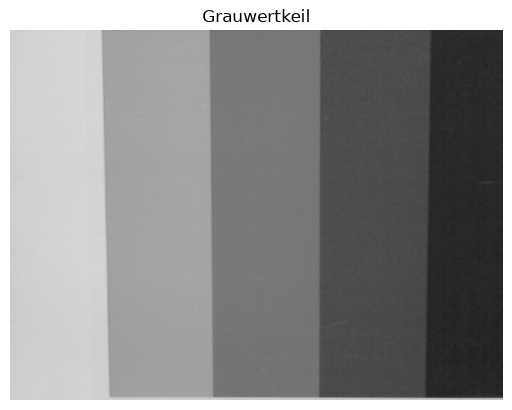

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

bild = cv2.imread("best.png")

graubild = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)

plt.imshow(graubild, cmap="gray", vmin=0, vmax=255)
plt.title("Grauwertkeil")
plt.axis("off")
plt.show()


In [4]:
print("Bildgroesse:", graubild.shape)
print("Datentyp:", graubild.dtype)

Bildgroesse: (480, 640)
Datentyp: uint8



### 1.2 Auswahl der Grauwertstufen

Aus jeder Grauwertstufe wird ein rechteckiger Bereich ohne Stufenraender ausgewaehlt.


In [7]:
bereiche = [graubild[100:380, 30:100], graubild[100:380, 160:230], graubild[100:380, 290:360], 
            graubild[100:380, 420:490], graubild[100:380, 550:620]]

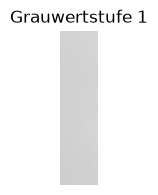

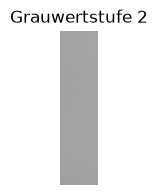

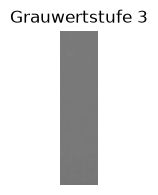

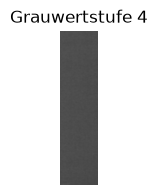

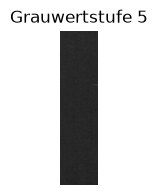

In [8]:
for i in range(len(bereiche)):
    plt.figure(figsize=(3, 2))
    plt.imshow(bereiche[i], cmap="gray", vmin=0, vmax=255)
    plt.title(f"Grauwertstufe {i+1}")
    plt.axis("off")
    plt.show()



### 1.3 Mittelwert und Standardabweichung

Fuer jede Grauwertstufe werden der Mittelwert und die Standardabweichung der Pixelwerte berechnet.


In [15]:
print("Stufe  Mittelwert  Standardabweichung")

for i in range(len(bereiche)):
    mittelwert = np.mean(bereiche[i])
    std = np.std(bereiche[i])

    print(f"{i+1:3d}  {mittelwert:10.2f}  {std:14.2f}")


Stufe  Mittelwert  Standardabweichung
  1      210.12            1.82
  2      163.96            1.61
  3      120.87            1.18
  4       76.54            2.03
  5       39.42            2.12



Die mittleren Grauwerte nehmen von Stufe 1 bis 5 ab.
Die Standardabweichungen sind relativ gering (1,18 bis 2,12).
Alle fuenf Grauwertstufen sind gut unterscheidbar.


---
## 2. Aufnahme eines Dunkelbildes

### 2.1 Berechnung des Dunkelbildes

Die zehn Dunkelaufnahmen werden eingelesen, in Grauwertbilder umgewandelt und pixelweise gemittelt.


In [18]:
dunkelbilder = []

for i in range(10):
    dateiname = f"black-white/black-{i}.png"

    bild = cv2.imread(dateiname)
    graubild_schwarz = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)

    dunkelbilder.append(graubild_schwarz.astype(float)) # Float fuer Berechnungen mit Dezimalwerten

dunkelbild = np.mean(dunkelbilder, axis=0) # Pixelweiser Mittelwert aus 10 Bildern

print("Bildgroesse:", dunkelbild.shape)
print("Mittlerer Grauwert:", np.mean(dunkelbild))
print("Minimum:", np.min(dunkelbild))
print("Maximum:", np.max(dunkelbild))


Bildgroesse: (480, 640)
Mittlerer Grauwert: 0.0007770182291666667
Minimum: 0.0
Maximum: 4.2


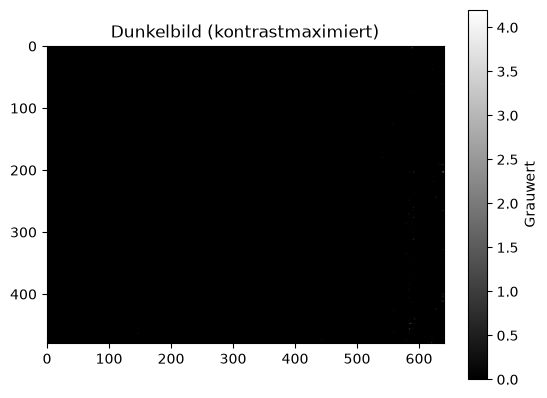

In [19]:
plt.imshow(dunkelbild, cmap="gray",
           vmin=np.min(dunkelbild),
           vmax=np.max(dunkelbild))

plt.title("Dunkelbild (kontrastmaximiert)")
plt.colorbar(label="Grauwert")
plt.show()


Das Dunkelbild zeigt einen sehr geringen mittleren Grauwert von etwa 0,0008.
Der maximale Grauwert betraegt 4,2. Die meisten Pixel haben einen Wert nahe 0.
Der Dunkeloffset der Kamera ist bei diesen Aufnahmeeinstellungen somit sehr gering.


In [20]:
np.save("dunkelbild.npy", dunkelbild)


### 2.2 Dunkelbildkorrektur

Zur Korrektur wird das Dunkelbild pixelweise vom Eingabebild subtrahiert.


In [22]:
def dunkelkorrektur(dateiname, dunkelbild):
    bild = cv2.imread(dateiname, cv2.IMREAD_GRAYSCALE)
    bild = bild.astype(float)

    korrigiert = bild - dunkelbild # Dunkeloffset pixelweise entfernen
    korrigiert = np.clip(korrigiert, 0, 255) # Grauwerte auf 0 bis 255 begrenzen 

    return korrigiert

bild_korrigiert = dunkelkorrektur("best.png", dunkelbild)

cv2.imwrite("best_dunkelkorrigiert.png", bild_korrigiert.astype(np.uint8))


True

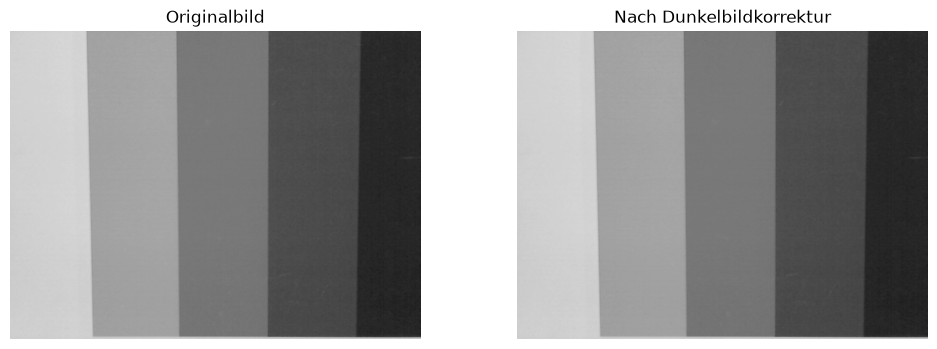

In [23]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(graubild, cmap="gray", vmin=0, vmax=255)
plt.title("Originalbild")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(bild_korrigiert, cmap="gray", vmin=0, vmax=255)
plt.title("Nach Dunkelbildkorrektur")
plt.axis("off")

plt.show()



## 3. Aufnahme eines Weissbildes

### 3.1 Berechnung des Weissbildes

Die zehn Weissaufnahmen werden eingelesen und pixelweise gemittelt. Anschliessend wird das Dunkelbild subtrahiert.


In [27]:
weissbilder = []

for i in range(10):
    dateiname = f"black-white/white-{i}.png"

    bild = cv2.imread(dateiname)
    graubild_weiss = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)

    weissbilder.append(graubild_weiss.astype(float))

weissmittel = np.mean(weissbilder, axis=0)

weissbild = weissmittel - dunkelbild #Dunkeloffset aus Weissbild entfernen

print("Bildgroesse:", weissbild.shape)
print("Mittlerer Grauwert:", np.mean(weissbild))
print("Minimum:", np.min(weissbild))
print("Maximum:", np.max(weissbild))


Bildgroesse: (480, 640)
Mittlerer Grauwert: 191.60787532552084
Minimum: 176.9
Maximum: 200.7


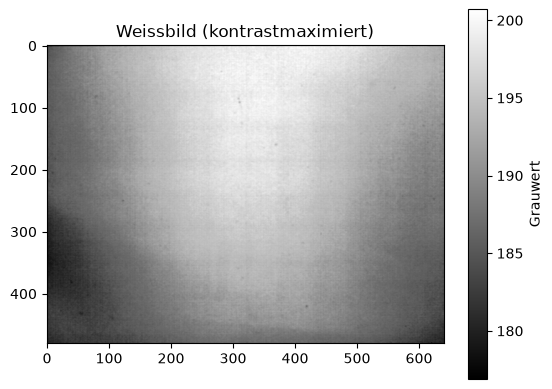

In [28]:
plt.imshow(weissbild, cmap="gray",
           vmin=np.min(weissbild),
           vmax=np.max(weissbild))

plt.title("Weissbild (kontrastmaximiert)")
plt.colorbar(label="Grauwert")
plt.show()



### 3.2 Normierung und Korrektur

Das Weissbild wird so normiert, dass sein Mittelwert 1 betraegt. Anschliessend wird das dunkelbildkorrigierte Eingabebild durch das normierte Weissbild dividiert.


In [31]:
weissbild_norm = weissbild / np.mean(weissbild) # Normierung auf Mittelwert 1

print("Mittelwert:", np.mean(weissbild_norm))
print("Minimum:", np.min(weissbild_norm))
print("Maximum:", np.max(weissbild_norm))


Mittelwert: 1.0
Minimum: 0.9232397139181583
Maximum: 1.0474517274356945


In [32]:
def bildkorrektur(dateiname, dunkelbild, weissbild_norm):
    bild = cv2.imread(dateiname, cv2.IMREAD_GRAYSCALE)
    bild = bild.astype(float)

    korrigiert = bild - dunkelbild # Dunkeloffset entfernen
    korrigiert = korrigiert / weissbild_norm # Ungleichmaessige Helligkeit ausgleichen

    korrigiert = np.clip(korrigiert, 0, 255) # Grauwerte begrenzen

    return korrigiert

bild_korrigiert = bildkorrektur(
    "best.png", dunkelbild, weissbild_norm
)

cv2.imwrite(
    "best_korrigiert.png",
    bild_korrigiert.astype(np.uint8)
)


True

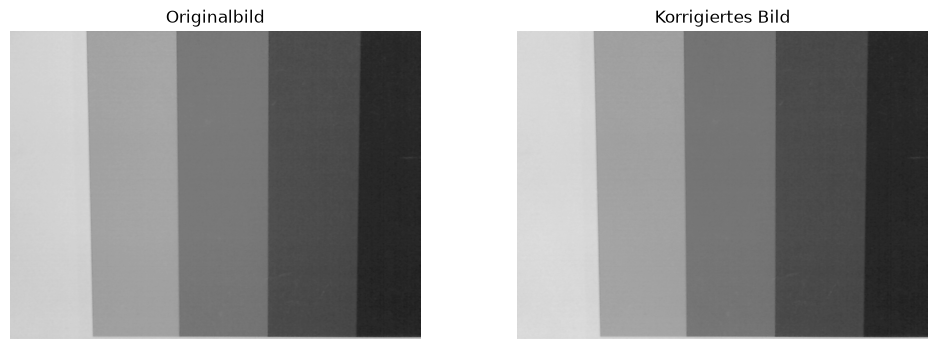

In [33]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(graubild, cmap="gray", vmin=0, vmax=255)
plt.title("Originalbild")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(bild_korrigiert, cmap="gray", vmin=0, vmax=255)
plt.title("Korrigiertes Bild")
plt.axis("off")

plt.show()


## 4. Pixelfehler
### 4.1 Vergleich vor und nach der Korrektur

Die Mittelwerte und Standardabweichungen der fuenf Grauwertstufen werden vor und nach der Korrektur verglichen.


In [41]:
bereiche_korrigiert = [
    bild_korrigiert[100:380, 30:100],
    bild_korrigiert[100:380, 160:230],
    bild_korrigiert[100:380, 290:360],
    bild_korrigiert[100:380, 420:490],
    bild_korrigiert[100:380, 550:620]
]

print("Stufe Mittelwert vorher Mittelwert nachher Std vorher Std nachher")

for i in range(5):
    mittelwert_vorher = np.mean(bereiche[i])
    mittelwert_nachher = np.mean(bereiche_korrigiert[i])

    std_vorher = np.std(bereiche[i])
    std_nachher = np.std(bereiche_korrigiert[i])

    print(f"{i+1:2d} {mittelwert_vorher:14.2f} {mittelwert_nachher:18.2f} {std_vorher:14.2f} {std_nachher:11.2f}")


Stufe Mittelwert vorher Mittelwert nachher Std vorher Std nachher
 1         210.12             215.78           1.82        1.65
 2         163.96             161.83           1.61        1.35
 3         120.87             117.30           1.18        1.02
 4          76.54              75.04           2.03        1.74
 5          39.42              39.46           2.12        1.98


#### Auswertung

Nach der Dunkelbild- und Weissbildkorrektur ist die Standardabweichung bei allen fünf Grauwertstufen gesunken.

Die größte relative Verbesserung zeigt die zweite Stufe mit etwa 16 %. Die Mittelwerte haben sich ebenfalls leicht verändert.

Die Kalibrierung hat somit die Gleichmäßigkeit der Grauwerte verbessert. Die verbleibenden Abweichungen können unter anderem durch Bildrauschen und Beleuchtungsunterschiede verursacht werden.

### 4.2 Untersuchung der Pixelfehler

In [56]:
# Median der 3x3 Umgebung
dunkel_median = cv2.medianBlur(dunkelbild.astype(np.float32), 3) 
weiss_median = cv2.medianBlur(weissbild.astype(np.float32), 3)


dunkel_abweichung = dunkelbild - dunkel_median # Pixel heller als Umgebung
weiss_abweichung = weiss_median - weissbild # Pixel dunkler als Umgebung

schwellwert = 3 

# Auffaellige Pixel bestimmen
hot_pixel = dunkel_abweichung > schwellwert
dead_pixel = weiss_abweichung > schwellwert

# Anzahl
print("Dunkelbild:", np.sum(hot_pixel), "auffaellige Pixel")
print("Weissbild:", np.sum(dead_pixel), "auffaellige Pixel")


Dunkelbild: 1 auffaellige Pixel
Weissbild: 1 auffaellige Pixel


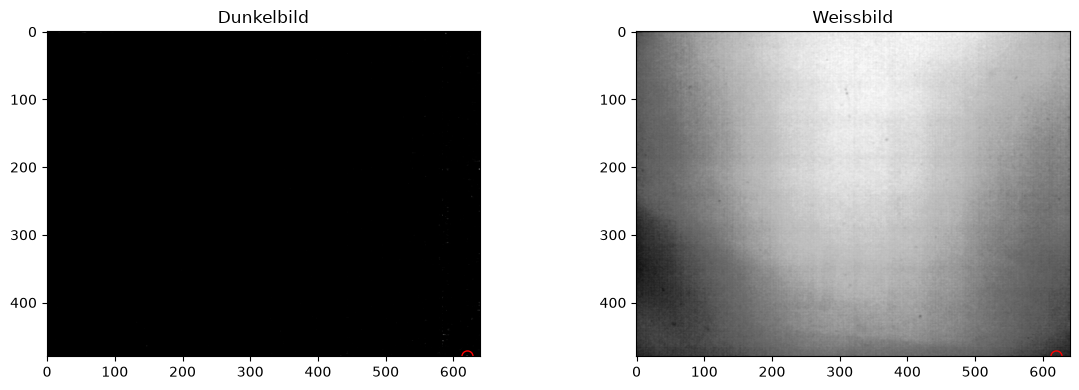

In [57]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(dunkelbild, cmap="gray")
plt.title("Dunkelbild")

# Koordinaten auffaeliger Pixel. Zeile & Spalte
for y, x in np.argwhere(hot_pixel):
    plt.plot(x, y, "ro", markersize=8, fillstyle="none")

plt.subplot(1, 2, 2)
plt.imshow(weissbild, cmap="gray")
plt.title("Weissbild")

# Markierung
for y, x in np.argwhere(dead_pixel):
    plt.plot(x, y, "ro", markersize=8, fillstyle="none")

plt.tight_layout()
plt.show()


In [46]:

print("Dunkelbild:", np.argwhere(hot_pixel))
print("Weissbild:", np.argwhere(dead_pixel))


Dunkelbild: [[479 620]]
Weissbild: [[479 620]]


#### Auswertung der Pixelfehler

Bei der Untersuchung des Dunkelbildes und des Weissbildes wurde jeweils ein auffälliger Pixel am rechten unteren Bildrand gefunden. Die Koordinaten stimmen überein.

Die maximalen lokalen Abweichungen betragen 3,8 Grauwertstufen im Dunkelbild und 3,9 im Weissbild.

Da die Abweichungen relativ gering sind, lässt sich nicht eindeutig feststellen, ob ein tatsächlicher Pixelfehler vorliegt.

## 5. Fazit

In diesem Versuch wurde eine Digitalkamera mithilfe eines Dunkelbildes und eines Weissbildes kalibriert.

Das Dunkelbild zeigte einen sehr geringen mittleren Grauwert von etwa 0,0008. Der Dunkeloffset hatte daher nur einen sehr kleinen Einfluss auf das aufgenommene Bild.

Im Weissbild waren deutliche Helligkeitsunterschiede zwischen der Bildmitte und den Bildrändern zu erkennen. Diese können unter anderem durch Vignettierung und ungleichmäßige Beleuchtung entstehen.

Nach der Korrektur des Grauwertkeils sank die Standardabweichung bei allen fünf Grauwertstufen. Die größte relative Verbesserung betrug etwa 16 %.

Bei der Untersuchung auf Pixelfehler wurde ein auffälliger Pixel gefunden, dessen Defekt jedoch nicht eindeutig nachgewiesen werden konnte.

**Insgesamt konnte die Kalibrierung die Gleichmäßigkeit der Grauwerte verbessern.**